In [2]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics.pairwise import cosine_similarity

print("Guestly Upsell Engine is ready!")


Guestly Upsell Engine is ready!


In [3]:

print("Welcome to Guestly!")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("All systems ready.")


Welcome to Guestly!
Pandas version: 2.3.3
NumPy version: 2.2.5
All systems ready.


In [6]:

# Load the hotel booking dataset

df = pd.read_csv("../data/hotel_bookings.csv")

# Display the first five records
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:

df.shape


(119390, 32)

In [8]:

df.columns


Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [9]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [10]:

df.head(10)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


In [11]:

df.tail()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


DATA EXPLORATION AND CLEANING

In [15]:

# Check dataset structure

df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 87396 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  object 
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_year               87396 non-null  int64  
 4   arrival_date_month              87396 non-null  object 
 5   arrival_date_week_number        87396 non-null  int64  
 6   arrival_date_day_of_month       87396 non-null  int64  
 7   stays_in_weekend_nights         87396 non-null  int64  
 8   stays_in_week_nights            87396 non-null  int64  
 9   adults                          87396 non-null  int64  
 10  children                        87392 non-null  float64
 11  babies                          87396 non-null  int64  
 12  meal                            8739

In [16]:

# Count missing values in each column

df.isnull().sum()


hotel                                 0
is_canceled                           0
lead_time                             0
arrival_date_year                     0
arrival_date_month                    0
arrival_date_week_number              0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              4
babies                                0
meal                                  0
country                             452
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
assigned_room_type                    0
booking_changes                       0
deposit_type                          0
agent                             12193
company                           82137


In [17]:

missing_values = df.isnull().sum()

missing_values[missing_values > 0].sort_values(
    ascending=False
)


company     82137
agent       12193
country       452
children        4
dtype: int64

In [18]:

# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)


Number of duplicate records: 0


In [19]:

# Statistical summary of numerical columns

df.describe()


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87392.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,75203.000000,5259.000000,87396.000000,87396.000000,87396.000000,87396.000000
mean,0.274898,79.891368,2016.210296,26.838334,15.815541,1.005263,2.625395,1.875795,0.138640,0.010824,0.039075,0.030413,0.183990,0.271603,94.138306,183.081384,0.749565,106.337246,0.084226,0.698567
std,0.446466,86.052325,0.686102,13.674572,8.835146,1.031921,2.053584,0.626500,0.455881,0.113597,0.193775,0.369145,1.731894,0.727245,113.188172,130.557608,10.015731,55.013953,0.281533,0.831946
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,47.000000,0.000000,72.000000,0.000000,0.000000
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,169.000000,0.000000,98.100000,0.000000,0.000000
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,263.000000,0.000000,134.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [20]:

# Number of adults
print("Adults:")
print(df["adults"].value_counts())

# Number of children
print("\nChildren:")
print(df["children"].value_counts())

# Customer types
print("\nCustomer types:")
print(df["customer_type"].value_counts())

# Reserved room types
print("\nRoom types:")
print(df["reserved_room_type"].value_counts())


Adults:
adults
2     64497
1     16503
3      5935
0       385
4        60
26        5
5         2
27        2
20        2
40        1
55        1
50        1
6         1
10        1
Name: count, dtype: int64

Children:
children
0.0     79028
1.0      4695
2.0      3593
3.0        75
10.0        1
Name: count, dtype: int64

Customer types:
customer_type
Transient          71986
Transient-Party    11727
Contract            3139
Group                544
Name: count, dtype: int64

Room types:
reserved_room_type
A    56552
D    17398
E     6049
F     2823
G     2052
B      999
C      915
H      596
L        6
P        6
Name: count, dtype: int64


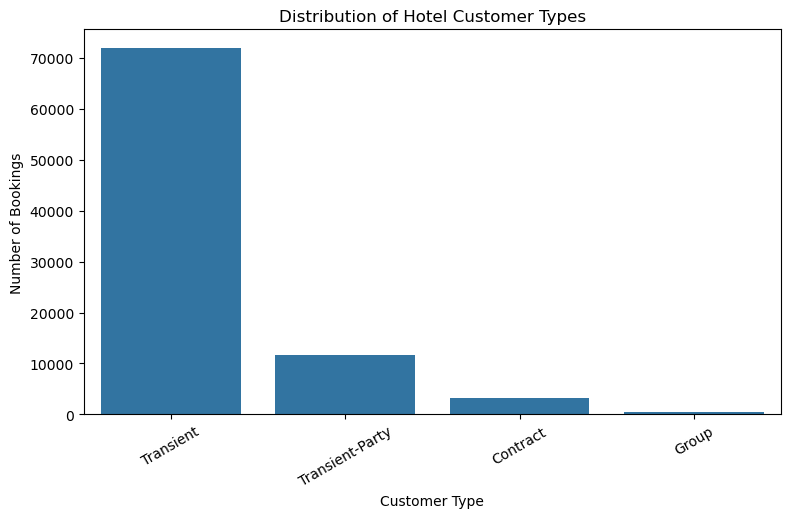

In [21]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="customer_type",
    order=df["customer_type"].value_counts().index
)

plt.title("Distribution of Hotel Customer Types")
plt.xlabel("Customer Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=30)

plt.show()


In [22]:

# Create a backup of the original dataset

df_clean = df.copy()

print("Backup created successfully.")


Backup created successfully.


In [23]:

# Handle missing company and agent information

df_clean["company"] = df_clean["company"].fillna(0)

df_clean["agent"] = df_clean["agent"].fillna(0)

print("Company and agent missing values handled.")


Company and agent missing values handled.


In [24]:

# Handle missing country information

df_clean["country"] = df_clean["country"].fillna("Unknown")

print("Country missing values handled.")


Country missing values handled.


In [25]:

# Handle missing children values

df_clean["children"] = df_clean["children"].fillna(0)

print("Children missing values handled.")


Children missing values handled.


In [26]:

# Check missing values after cleaning

df_clean.isnull().sum()


hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [27]:

# Check unusual booking records

print("Bookings with zero adults:")
print((df_clean["adults"] == 0).sum())

print("\nBookings with negative room rates:")
print((df_clean["adr"] < 0).sum())

print("\nBookings with zero nights:")
print(
    (
        (df_clean["stays_in_weekend_nights"] == 0) &
        (df_clean["stays_in_week_nights"] == 0)
    ).sum()
)

print("\nBookings with unusually large guest counts:")
print(
    (df_clean["adults"] + df_clean["children"] +
     df_clean["babies"] > 10).sum()
)


Bookings with zero adults:
385

Bookings with negative room rates:
1

Bookings with zero nights:
651

Bookings with unusually large guest counts:
14


In [28]:

print("Duplicates:", df_clean.duplicated().sum())


Duplicates: 0


In [29]:

# Feature engineering

# Total number of guests
df_clean["total_guests"] = (
    df_clean["adults"] +
    df_clean["children"] +
    df_clean["babies"]
)

# Total nights stayed
df_clean["total_nights"] = (
    df_clean["stays_in_weekend_nights"] +
    df_clean["stays_in_week_nights"]
)

# Identify family bookings
df_clean["is_family"] = (
    (df_clean["children"] > 0) |
    (df_clean["babies"] > 0)
).astype(int)

# Check the new columns
df_clean[
    ["adults", "children", "babies",
     "total_guests", "total_nights", "is_family"]
].head(10)


,adults,children,babies,total_guests,total_nights,is_family
0,2,0.0,0,2.0,0,0
1,2,0.0,0,2.0,0,0
2,1,0.0,0,1.0,1,0
3,1,0.0,0,1.0,1,0
4,2,0.0,0,2.0,2,0
6,2,0.0,0,2.0,2,0
7,2,0.0,0,2.0,2,0
8,2,0.0,0,2.0,3,0
9,2,0.0,0,2.0,3,0
10,2,0.0,0,2.0,4,0


In [30]:

# Final cleaning report

print("Original dataset shape:", df.shape)

print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nNew features:")
print([
    "total_guests",
    "total_nights",
    "is_family"
])


Original dataset shape: (87396, 32)
Cleaned dataset shape: (87396, 35)

Remaining missing values:
0

Duplicate records:
0

New features:
['total_guests', 'total_nights', 'is_family']


In [31]:

# Save cleaned dataset

df_clean.to_csv(
    "../data/hotel_bookings_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [32]:

# Create a catalogue of additional hotel services

services = pd.DataFrame({

    "service_name": [
        "Breakfast Package",
        "Airport Pickup",
        "Spa Package",
        "Late Checkout",
        "Room Upgrade",
        "Laundry Service",
        "Family Package"
    ],

    "category": [
        "Food",
        "Transport",
        "Wellness",
        "Comfort",
        "Accommodation",
        "Convenience",
        "Family"
    ],

    "family_friendly": [
        1, 0, 0, 0, 1, 1, 1
    ],

    "long_stay": [
        1, 0, 0, 1, 0, 1, 1
    ],

    "business_friendly": [
        0, 1, 0, 1, 1, 0, 0
    ],

    "requires_flight": [
        0, 1, 0, 0, 0, 0, 0
    ],

    "requires_interest": [
        0, 0, 1, 0, 0, 0, 0
    ]
})

# Display the service catalogue

services


,service_name,category,family_friendly,long_stay,business_friendly,requires_flight,requires_interest
0,Breakfast Package,Food,1,1,0,0,0
1,Airport Pickup,Transport,0,0,1,1,0
2,Spa Package,Wellness,0,0,0,0,1
3,Late Checkout,Comfort,0,1,1,0,0
4,Room Upgrade,Accommodation,1,0,1,0,0
5,Laundry Service,Convenience,1,1,0,0,0
6,Family Package,Family,1,1,0,0,0


In [33]:

# Select one booking from our cleaned dataset

guest = df_clean.iloc[0]

# Display important guest information

guest_profile = {
    "adults": guest["adults"],
    "children": guest["children"],
    "total_guests": guest["total_guests"],
    "total_nights": guest["total_nights"],
    "is_family": guest["is_family"],
    "customer_type": guest["customer_type"],
    "meal": guest["meal"],
    "room_type": guest["reserved_room_type"]
}

# Display guest profile

print("GUEST PROFILE")
print("-------------------")

for key, value in guest_profile.items():
    print(f"{key}: {value}")


GUEST PROFILE
-------------------
adults: 2
children: 0.0
total_guests: 2.0
total_nights: 0
is_family: 0
customer_type: Transient
meal: BB
room_type: C


In [34]:

def recommend_services(guest):

    recommendations = []

    # Family recommendation
    if guest["is_family"] == 1:
        recommendations.append("Family Package")

    # Long-stay recommendation
    if guest["total_nights"] >= 3:
        recommendations.append("Laundry Service")

    # Breakfast recommendation
    if guest["meal"] not in ["BB", "HB", "FB"]:
        recommendations.append("Breakfast Package")

    # Business guest recommendation
    if guest["customer_type"] == "Transient":
        recommendations.append("Late Checkout")

    return recommendations


# Generate recommendations

recommended = recommend_services(guest_profile)

print("PERSONALIZED RECOMMENDATIONS")
print("----------------------------")

for service in recommended:
    print("-", service)


PERSONALIZED RECOMMENDATIONS
----------------------------
- Late Checkout
